In [1]:
# ! means that it runs through terminal
!pip install zerosyl

!pip install tgt

# wget downloads things directly from the internet
!wget https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.flac
!wget https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.TextGrid

--2026-10-19 20:47:16--  https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.flac
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.47.27, 192.178.54.27, 142.251.216.155, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.47.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 44534 (43K) [audio/flac]
Saving to: ‘5895-34629-0010.flac’

5895-34629-0010.fla 100%[===================>]  43.49K   139KB/s    in 0.3s    

2026-10-19 20:47:19 (139 KB/s) - ‘5895-34629-0010.flac’ saved [44534/44534]

--2026-10-19 20:47:19--  https://storage.googleapis.com/zerospeech-checkpoints/5895-34629-0010.TextGrid
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.170.155, 142.251.47.27, 142.251.47.59, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.170.155|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2880 (2.8K) [application/octet-stream]
Saving to: ‘5

In [2]:
# import all relevant functions and or libraries
import matplotlib.pyplot as plt
import numpy as np
import tgt
import torch
import torchaudio
from IPython.display import Audio, display
from scipy.cluster.hierarchy import cut_tree, linkage
from scipy.signal import find_peaks

from zerosyl import WavLM

plt.rcParams["font.family"] = "monospace"

In [3]:

# create an instance of wavlm model with pretrained weights gotten from "remote"
wavlm = WavLM.from_remote()



In [23]:
# wav contains the audio data, where as sr contains the sample rate of the audio (hz)
wav, sr = torchaudio.load("HendrikPhrase.flac")
# here we can see that sr matches the rate we display the audio at (16000 hz)
print(f"Original sample rate: {sr}")
display(Audio(wav, rate=16000))

Original sample rate: 16000


In [24]:
# preprocessing of the waveform
# loudness normalization
wav = torch.nn.functional.layer_norm(wav, wav.shape) # this ensures that one audio recording with very loud audio and another one with soft audio are both normalized to be the same aduio
# zero-pad such that the output features will be perfectly aligned with 20ms intervals
wav = torch.nn.functional.pad(wav, ((400 - 320) // 2, (400 - 320) // 2))

In [25]:
#Extract boundary features from layer 13
# the model has x amount of layers, at the 13th layer, we extract the feature vectors and look at what is going on in them 
# note how we are doing it for our audio sampe wav, so the features we extract will be unique to wav
with torch.inference_mode():
    boundary_features, _ = wavlm.extract_features(wav, output_layer=13)

# some kind of normalization or reduction technique

#numpy turns py torch tensor to numpy array. Changes data format, makes it easier to work with
#squeeze(0) removes the 0th dimension
    #Original shape: [1, time_steps, feature_dim]
    #After squeeze: [time_steps, feature_dim]
boundary_features = boundary_features.squeeze(0).cpu().numpy()

#display how many/ dimensionality of vectors [time_steps/ frames = 108, feature_dim = 1024]
# note feature dimension depends on lm model used, since we use wavLM large, it will alwys be 1024
boundary_features.shape

(181, 1024)

In [26]:
#Perform boundary detection using peak detection on smoothed L2 norms

# compute the L2 norm signal
norms = np.linalg.norm(boundary_features, axis=-1)
#print(norms) gives you 108 distances, i.e. the magnitudes of the vectors
# normalize the norm signal
norms = (norms - norms.mean()) / norms.std()
# takes those magniturdes and normalises them so that they are centered around 0


# smooth the L2 norm signal
kernel = np.ones(3) / 3 # kernal is moving average, takes average of 3 neigbouring values
pad_len = 3 // 2 # pad_len adds one value on each side of norms vector, both on start and finish, adding 2 in total
norms_padded = np.pad(norms, (pad_len, pad_len), mode="edge") # adds padding to norms, makes smoothing possible
norms_smooth = np.convolve(norms_padded, kernel, mode="valid") # averages out values so that you get less jaggedness

# why smooth?
#Removes high-frequency noise
#Emphasizes meaningful acoustic changes
#Reduces false positives in peak detection

# performan prominence based peak detection
peaks, _ = find_peaks(norms_smooth, prominence=0.45)
# 0.45 is the minimum height relative to surrounding valeys for a peak to be detected
print(peaks)

# use peaks to detemine boundaries
boundaries = [0] + peaks.tolist() + [len(boundary_features)] # very simply adding start and finish to boundraries
print(boundaries)

[ 18  24  36  46  58  69  73  80  90 102 113 119 129 148 156 174]
[0, 18, 24, 36, 46, 58, 69, 73, 80, 90, 102, 113, 119, 129, 148, 156, 174, 181]


In [27]:


textgrid = tgt.read_textgrid("HendrikPhrase.TextGrid")
# textgrid = None



In [28]:
# compute mel spectrogram
tMel = torchaudio.transforms.MelSpectrogram(
    n_fft=1024,
    win_length=400,
    hop_length=320,
)
tDB = torchaudio.transforms.AmplitudeToDB(top_db=80) #log scale: changes its scale to better match human perception (higher frequencies are harder to distinguish for humans than lower ones)

melspec = tDB(tMel(wav.squeeze()))

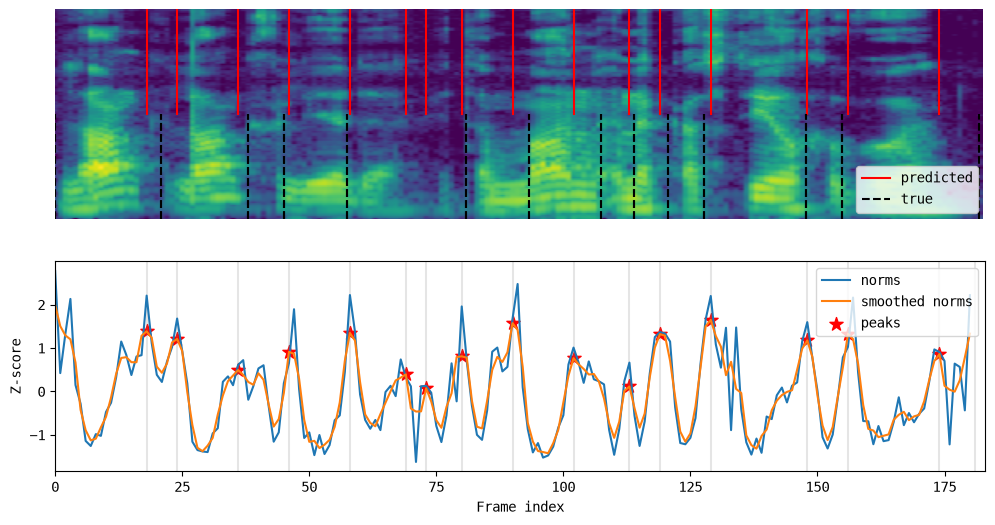

In [29]:


xmin, xmax = 0, melspec.size(1)

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for i, b in enumerate(peaks):
    plt.axvline(b, ymin=0.5, c="r", label="predicted" if i == 0 else None)

if not textgrid is None:
    for i, interval in enumerate(textgrid.get_tier_by_name("syllables")):
        x1 = interval.start_time * 50
        x2 = interval.end_time * 50
        plt.axvline(
            x1, ymax=0.5, c="k", linestyle="--", label="true" if i == 0 else None
        )
        plt.axvline(x2, ymax=0.5, c="k", linestyle="--")
plt.xlim(xmin, xmax)
plt.legend()

plt.subplot(2, 1, 2)
for b in boundaries:
    plt.axvline(b, c="gray", alpha=0.2)

peaks_x = peaks
peaks_y = norms_smooth[peaks_x]

plt.plot(norms, label="norms")
plt.plot(norms_smooth, label="smoothed norms")
plt.scatter(peaks_x, peaks_y, marker="*", label="peaks", color="red", s=100)
plt.xlim(xmin, xmax)
plt.xlabel("Frame index")
plt.ylabel("Z-score")
plt.legend()



In [31]:


listen_samples = []
listen_samples.append(np.zeros(8000))
for start_frame, end_frame in zip(boundaries[:-1], boundaries[1:]):
    listen_samples.append(wav[0, start_frame * 320 : end_frame * 320])
    listen_samples.append(np.zeros(8000))
listen_samples = np.concat(listen_samples, axis=0)
display(Audio(listen_samples, rate=16000))



In [32]:
# now extract semantic features from higher layer (22)
# what is a semantic? it is meaning, low is fact, higher is meaning
with torch.inference_mode():
    semantic_features, _ = wavlm.extract_features(wav, output_layer=22)

semantic_features = semantic_features.squeeze(0)

semantic_features.shape

torch.Size([181, 1024])

In [33]:
starts = torch.tensor(boundaries[:-1], device=wav.device)
ends = torch.tensor(boundaries[1:], device=wav.device)
embeddings = [
    semantic_features[start:end].mean(dim=0) for start, end in zip(starts, ends)
]
embeddings = torch.stack(embeddings)

In [34]:
embeddings.shape

torch.Size([17, 1024])

In [35]:


# Load the K-Means centroids
centroids = torch.hub.load_state_dict_from_url(
    "https://storage.googleapis.com/zerospeech-checkpoints/zerosyl-v040-centroids-k-10000.pt"
)
# Find the ID of the nearest centroid
ids = torch.cdist(embeddings.cpu(), centroids).argmin(1)



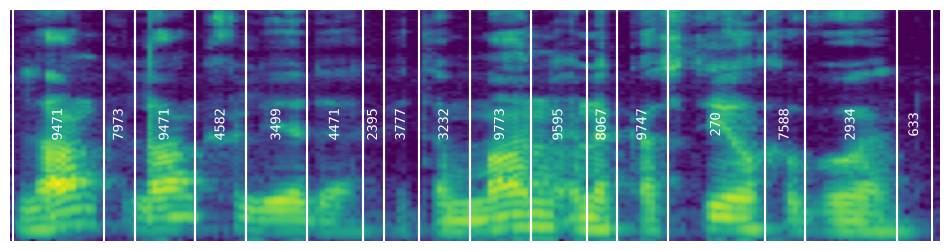

In [36]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for b1, b2, id in zip(boundaries[:-1], boundaries[1:], ids):
    plt.axvline(b1, c="w")
    plt.axvline(b2, c="w")
    plt.text(
        (b1 + b2) / 2, 64, str(id.item()), rotation=90, c="w", ha="center", va="center"
    )


In [37]:


# agglomerative clustering
linkage_matrix = linkage(
    centroids.numpy(), method="ward", metric="euclidean", optimal_ordering=False
)
# cut dendrogram into 2 main branches
silences = cut_tree(linkage_matrix, 2)[:, 0]
# the smaller branch should be silences
if silences.sum() > (1 - silences).sum():
    silences = 1 - silences
# to torch tensor
silences = torch.from_numpy(silences).bool()



In [38]:
print(silences[ids])

tensor([False, False, False, False, False, False,  True, False, False, False,
        False, False, False, False, False, False,  True])


In [39]:
order = torch.argsort(silences)  # [0,0,....,0,0,1,1,...,1,1]
SIL = torch.argmax(silences[order].long()).item()  # position of first 1
mapping = torch.empty_like(order)
mapping[order] = torch.arange(len(order))
mapping[mapping > SIL] = SIL

print(f"The new (single) silence token has the ID: {SIL}")

The new (single) silence token has the ID: 9115


In [40]:
ids_remapped = mapping[ids]

ids_remapped

tensor([3299, 3739, 3299, 7784, 7517, 7826, 9115, 7630, 8440, 3005, 3442, 4565,
        3093, 6399, 4096, 8972, 9115])

In [41]:


not_repeated = torch.ones_like(ids_remapped, dtype=torch.bool)
not_repeated[1:] = ~torch.logical_and(
    ids_remapped[1:] == ids_remapped[:-1], ids_remapped[1:] == SIL
)
is_end = torch.ones_like(ids_remapped, dtype=torch.bool)
is_end[:-1] = ~torch.logical_and(
    ids_remapped[1:] == ids_remapped[:-1], ids_remapped[1:] == SIL
)
starts_merged = starts[not_repeated]
ends_merged = ends[is_end]
ids_merged = ids_remapped[not_repeated]



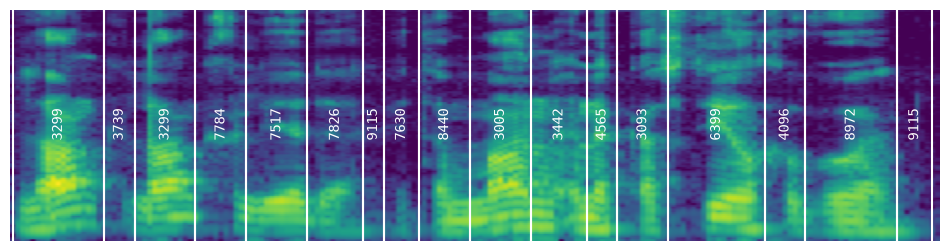

In [42]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 1, 1)
plt.imshow(melspec, aspect="auto", origin="lower")
plt.axis("off")
for start, end, id in zip(starts_merged, ends_merged, ids_merged):
    plt.axvline(start, c="w")
    plt.axvline(end, c="w")
    plt.text(
        (start + end) / 2,
        64,
        str(id.item()),
        rotation=90,
        c="w",
        ha="center",
        va="center",
    )